In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display


# PROJECT PATHS


PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

EVALUATION_DIR = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "environmental_anomalies"
    / "ifs_baseline_evaluation_2024_2025"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "environmental_anomalies"
    / "ifs_baseline_evaluation_2024_2025"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)


# DISPLAY SETTINGS


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

print("Project directory:", PROJECT_DIR)
print("Evaluation directory:", EVALUATION_DIR)
print("Report directory:", REPORT_DIR)

print("\nNotebook environment configured successfully.")

Project directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave
Evaluation directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\environmental_anomalies\ifs_baseline_evaluation_2024_2025
Report directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\reports\environmental_anomalies\ifs_baseline_evaluation_2024_2025

Notebook environment configured successfully.


In [3]:

# CELL 2: LOAD EVALUATION DATASETS

# Define file paths
TEST_FILE = EVALUATION_DIR / "ifs_anomaly_test_2024_2025.csv"
METRICS_FILE = EVALUATION_DIR / "ifs_anomaly_evaluation_metrics.csv"
DISTRICT_FILE = EVALUATION_DIR / "ifs_anomaly_district_metrics.csv"
MONTHLY_FILE = EVALUATION_DIR / "ifs_anomaly_monthly_metrics.csv"

# Check whether all files exist
files = {
    "Test classifications": TEST_FILE,
    "Overall metrics": METRICS_FILE,
    "District metrics": DISTRICT_FILE,
    "Monthly metrics": MONTHLY_FILE
}

print("=" * 65)
print("EVALUATION FILE VALIDATION")
print("=" * 65)

for name, path in files.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

missing_files = [
    name for name, path in files.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing evaluation files: {missing_files}"
    )

# Load datasets
test_df = pd.read_csv(TEST_FILE, parse_dates=["date"])
metrics_df = pd.read_csv(METRICS_FILE)
district_metrics_df = pd.read_csv(DISTRICT_FILE)
monthly_metrics_df = pd.read_csv(MONTHLY_FILE)

# Display dataset dimensions
print("\n" + "=" * 65)
print("DATASET DIMENSIONS")
print("=" * 65)

datasets = {
    "Test classifications": test_df,
    "Overall metrics": metrics_df,
    "District metrics": district_metrics_df,
    "Monthly metrics": monthly_metrics_df
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

# Display column names
print("\n" + "=" * 65)
print("DATASET COLUMNS")
print("=" * 65)

for name, df in datasets.items():
    print(f"\n{name}")
    print(df.columns.tolist())

print("\nAll four evaluation datasets loaded successfully.")

EVALUATION FILE VALIDATION
Test classifications: FOUND
Overall metrics: FOUND
District metrics: FOUND
Monthly metrics: FOUND

DATASET DIMENSIONS
Test classifications: (18275, 9)
Overall metrics: (3, 12)
District metrics: (75, 13)
Monthly metrics: (36, 13)

DATASET COLUMNS

Test classifications
['district', 'date', 'rainfall_era5_anomaly', 'temperature_era5_anomaly', 'humidity_era5_anomaly', 'rainfall_ifs_anomaly', 'temperature_ifs_anomaly', 'humidity_ifs_anomaly', 'month']

Overall metrics
['variable', 'records', 'reference_anomalies', 'comparison_anomalies', 'true_positive', 'true_negative', 'false_positive', 'false_negative', 'overall_agreement', 'precision', 'recall', 'f1_score']

District metrics
['records', 'reference_anomalies', 'comparison_anomalies', 'true_positive', 'true_negative', 'false_positive', 'false_negative', 'overall_agreement', 'precision', 'recall', 'f1_score', 'district', 'variable']

Monthly metrics
['records', 'reference_anomalies', 'comparison_anomalies', 'true

In [4]:
# ==================================================
# CELL 3: EVALUATION DATA QUALITY CHECKS
# ==================================================

print("=" * 65)
print("EVALUATION DATA QUALITY CHECKS")
print("=" * 65)

# --------------------------------------------------
# 1. Missing values
# --------------------------------------------------

print("\n1. MISSING VALUE ANALYSIS")

for name, df in datasets.items():
    missing = df.isnull().sum().sum()
    print(f"{name}: {missing} missing values")

# --------------------------------------------------
# 2. Duplicate records
# --------------------------------------------------

print("\n2. DUPLICATE RECORD ANALYSIS")

print(
    "Test district-date duplicates:",
    test_df.duplicated(["district", "date"]).sum()
)

print(
    "Duplicate overall metric variables:",
    metrics_df.duplicated(["variable"]).sum()
)

print(
    "Duplicate district-variable combinations:",
    district_metrics_df.duplicated(["district", "variable"]).sum()
)

print(
    "Duplicate month-variable combinations:",
    monthly_metrics_df.duplicated(["month", "variable"]).sum()
)

# --------------------------------------------------
# 3. Metric range validation
# --------------------------------------------------

metric_columns = [
    "overall_agreement",
    "precision",
    "recall",
    "f1_score"
]

print("\n3. METRIC RANGE VALIDATION")

for name, df in datasets.items():
    if all(col in df.columns for col in metric_columns):
        invalid = (
            (df[metric_columns] < 0) |
            (df[metric_columns] > 1)
        ).sum().sum()

        print(f"{name}: {invalid} values outside [0, 1]")

# --------------------------------------------------
# 4. Confusion matrix count validation
# --------------------------------------------------

print("\n4. CONFUSION MATRIX VALIDATION")

for name, df in {
    "Overall": metrics_df,
    "District": district_metrics_df,
    "Monthly": monthly_metrics_df
}.items():

    total = (
        df["true_positive"]
        + df["true_negative"]
        + df["false_positive"]
        + df["false_negative"]
    )

    invalid = (total != df["records"]).sum()

    print(f"{name}: {invalid} inconsistent records")

# --------------------------------------------------
# 5. Classification balance
# --------------------------------------------------

print("\n5. TEST CLASSIFICATION BALANCE")

flag_columns = [
    "rainfall_era5_anomaly",
    "temperature_era5_anomaly",
    "humidity_era5_anomaly",
    "rainfall_ifs_anomaly",
    "temperature_ifs_anomaly",
    "humidity_ifs_anomaly"
]

display(
    test_df[flag_columns]
    .sum()
    .rename("Anomaly_Count")
    .to_frame()
)

print("\nData quality checks completed.")

EVALUATION DATA QUALITY CHECKS

1. MISSING VALUE ANALYSIS
Test classifications: 0 missing values
Overall metrics: 0 missing values
District metrics: 0 missing values
Monthly metrics: 0 missing values

2. DUPLICATE RECORD ANALYSIS
Test district-date duplicates: 0
Duplicate overall metric variables: 0
Duplicate district-variable combinations: 0
Duplicate month-variable combinations: 0

3. METRIC RANGE VALIDATION
Overall metrics: 0 values outside [0, 1]
District metrics: 0 values outside [0, 1]
Monthly metrics: 0 values outside [0, 1]

4. CONFUSION MATRIX VALIDATION
Overall: 0 inconsistent records
District: 0 inconsistent records
Monthly: 0 inconsistent records

5. TEST CLASSIFICATION BALANCE


,Anomaly_Count
rainfall_era5_anomaly,326
temperature_era5_anomaly,1158
humidity_era5_anomaly,502
rainfall_ifs_anomaly,569
temperature_ifs_anomaly,1578
humidity_ifs_anomaly,1166



Data quality checks completed.


ERA5 VS IFS ANOMALY COUNT COMPARISON


,Variable,ERA5_Anomalies,IFS_Anomalies,Difference
0,Rainfall,326,569,243
1,Temperature,1158,1578,420
2,Relative Humidity,502,1166,664


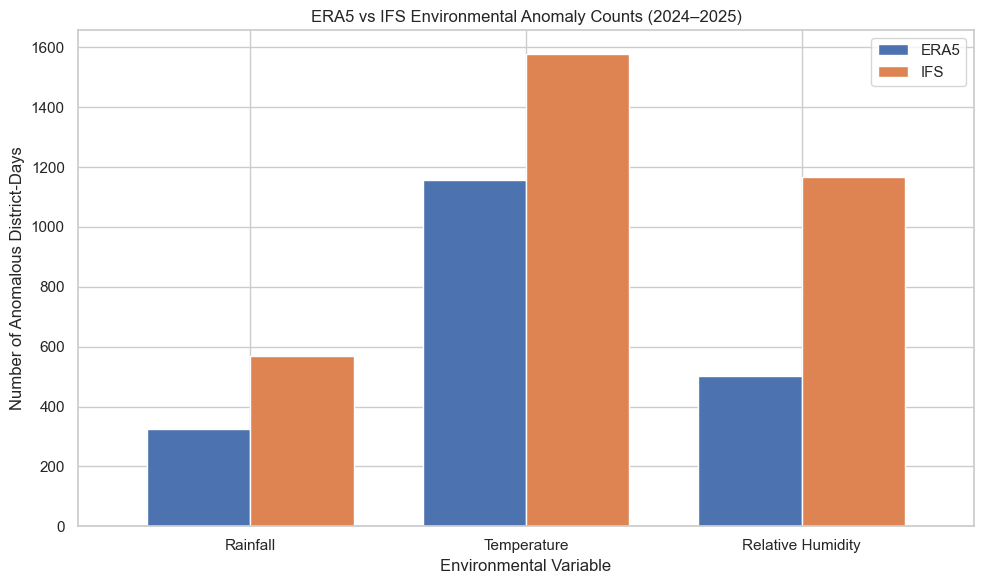


Comparison table saved successfully.


In [5]:
# ==================================================
# CELL 4: OVERALL ANOMALY COUNT COMPARISON
# ==================================================

print("=" * 65)
print("ERA5 VS IFS ANOMALY COUNT COMPARISON")
print("=" * 65)

variables = {
    "Rainfall": (
        "rainfall_era5_anomaly",
        "rainfall_ifs_anomaly"
    ),
    "Temperature": (
        "temperature_era5_anomaly",
        "temperature_ifs_anomaly"
    ),
    "Relative Humidity": (
        "humidity_era5_anomaly",
        "humidity_ifs_anomaly"
    )
}

comparison_results = []

for variable, columns in variables.items():

    era5_column, ifs_column = columns

    era5_count = test_df[era5_column].sum()
    ifs_count = test_df[ifs_column].sum()

    difference = ifs_count - era5_count

    comparison_results.append({
        "Variable": variable,
        "ERA5_Anomalies": int(era5_count),
        "IFS_Anomalies": int(ifs_count),
        "Difference": int(difference)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

# --------------------------------------------------
# Visual comparison
# --------------------------------------------------

comparison_plot = comparison_df.set_index("Variable")[
    ["ERA5_Anomalies", "IFS_Anomalies"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title(
    "ERA5 vs IFS Environmental Anomaly Counts (2024–2025)"
)

ax.set_xlabel("Environmental Variable")
ax.set_ylabel("Number of Anomalous District-Days")

ax.tick_params(axis="x", rotation=0)
ax.legend(["ERA5", "IFS"])

plt.tight_layout()
plt.show()

# --------------------------------------------------
# Save comparison table
# --------------------------------------------------

comparison_df.to_csv(
    REPORT_DIR / "overall_anomaly_count_comparison.csv",
    index=False
)

print("\nComparison table saved successfully.")

In [6]:
# ==================================================
# CELL 5: DISTRICT-LEVEL ANOMALY COMPARISON
# ==================================================

print("=" * 65)
print("DISTRICT-LEVEL ANOMALY COMPARISON")
print("=" * 65)

# Select anomaly count columns
district_comparison = district_metrics_df[
    [
        "district",
        "variable",
        "reference_anomalies",
        "comparison_anomalies"
    ]
].copy()

# Calculate difference
district_comparison["difference"] = (
    district_comparison["comparison_anomalies"]
    - district_comparison["reference_anomalies"]
)

# Sort by variable and difference
district_comparison = district_comparison.sort_values(
    ["variable", "difference"],
    ascending=[True, False]
)

# Display top 5 districts for each variable
for variable in district_comparison["variable"].unique():

    print(f"\nTOP 5 DISTRICTS: {variable}")

    result = (
        district_comparison[
            district_comparison["variable"] == variable
        ]
        .head(5)
    )

    display(result)

# --------------------------------------------------
# Save district comparison
# --------------------------------------------------

district_comparison.to_csv(
    REPORT_DIR / "district_anomaly_count_comparison.csv",
    index=False
)

print("\nDistrict comparison saved successfully.")

DISTRICT-LEVEL ANOMALY COMPARISON

TOP 5 DISTRICTS: precipitation_sum


,district,variable,reference_anomalies,comparison_anomalies,difference
9,Batticaloa,precipitation_sum,7,38,31
12,Colombo,precipitation_sum,15,33,18
39,Kurunegala,precipitation_sum,13,29,16
66,Ratnapura,precipitation_sum,12,28,16
15,Galle,precipitation_sum,12,27,15



TOP 5 DISTRICTS: relative_humidity_2m_mean


,district,variable,reference_anomalies,comparison_anomalies,difference
29,Kalutara,relative_humidity_2m_mean,20,104,84
17,Galle,relative_humidity_2m_mean,18,75,57
50,Matara,relative_humidity_2m_mean,17,73,56
68,Ratnapura,relative_humidity_2m_mean,24,73,49
35,Kegalle,relative_humidity_2m_mean,20,67,47



TOP 5 DISTRICTS: temperature_2m_mean


,district,variable,reference_anomalies,comparison_anomalies,difference
25,Jaffna,temperature_2m_mean,48,123,75
37,Kilinochchi,temperature_2m_mean,44,87,43
67,Ratnapura,temperature_2m_mean,55,96,41
34,Kegalle,temperature_2m_mean,41,80,39
64,Puttalam,temperature_2m_mean,52,88,36



District comparison saved successfully.


DISTRICT-LEVEL ANOMALY DIFFERENCE VISUALIZATION


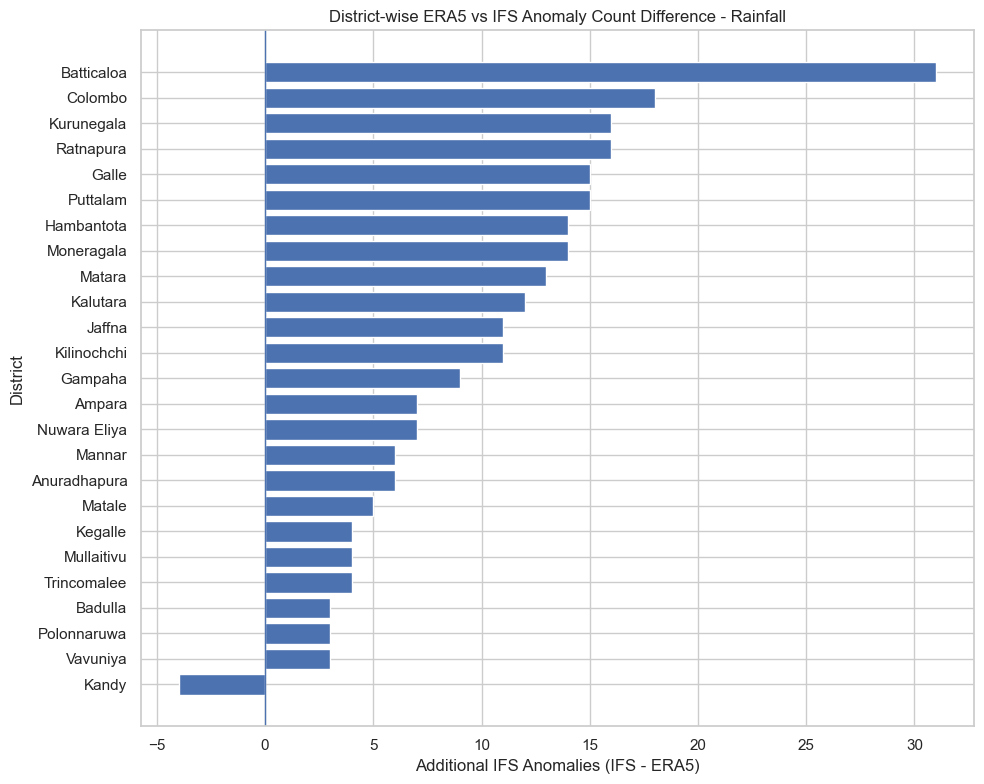

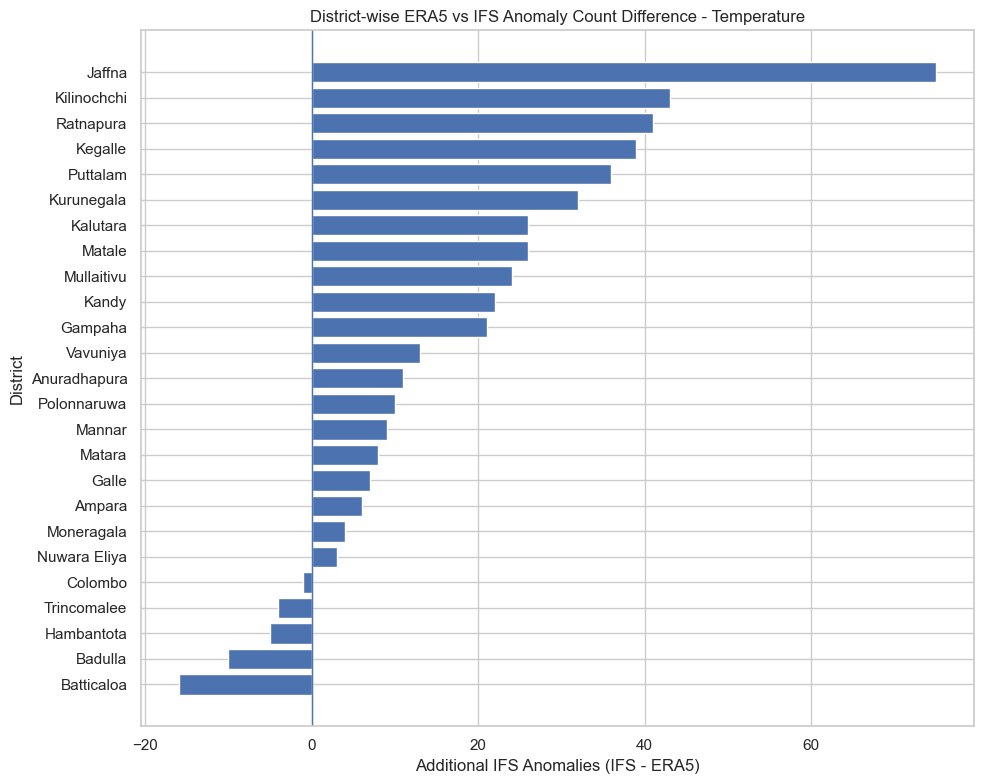

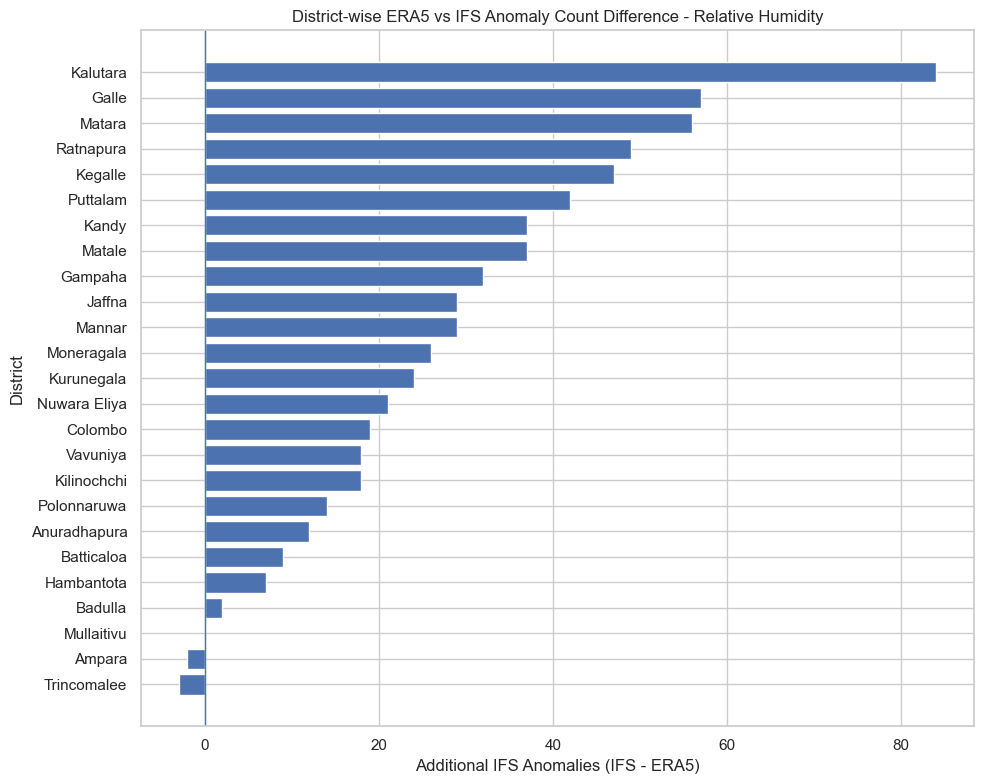


All three district-level charts saved successfully.


In [7]:
# ==================================================
# CELL 6: DISTRICT-LEVEL DIFFERENCE VISUALIZATION
# ==================================================

print("=" * 65)
print("DISTRICT-LEVEL ANOMALY DIFFERENCE VISUALIZATION")
print("=" * 65)

variable_names = {
    "precipitation_sum": "Rainfall",
    "temperature_2m_mean": "Temperature",
    "relative_humidity_2m_mean": "Relative Humidity"
}

for variable, display_name in variable_names.items():

    plot_df = district_comparison[
        district_comparison["variable"] == variable
    ].copy()

    plot_df = plot_df.sort_values(
        "difference",
        ascending=True
    )

    plt.figure(figsize=(10, 8))

    plt.barh(
        plot_df["district"],
        plot_df["difference"]
    )

    plt.title(
        f"District-wise ERA5 vs IFS Anomaly Count Difference - {display_name}"
    )

    plt.xlabel("Additional IFS Anomalies (IFS - ERA5)")
    plt.ylabel("District")

    plt.axvline(0, linewidth=1)

    plt.tight_layout()

    # Save figure
    filename = f"district_difference_{variable}.png"

    plt.savefig(
        REPORT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

print("\nAll three district-level charts saved successfully.")

In [8]:
# ==================================================
# CELL 7: MONTHLY ANOMALY COUNT COMPARISON
# ==================================================

print("=" * 65)
print("MONTHLY ERA5 VS IFS ANOMALY COMPARISON")
print("=" * 65)

monthly_comparison = monthly_metrics_df[
    [
        "month",
        "variable",
        "reference_anomalies",
        "comparison_anomalies"
    ]
].copy()

# Calculate differences
monthly_comparison["difference"] = (
    monthly_comparison["comparison_anomalies"]
    - monthly_comparison["reference_anomalies"]
)

# Month names
monthly_comparison["month_name"] = (
    pd.to_datetime(
        monthly_comparison["month"],
        format="%m"
    ).dt.strftime("%B")
)

# Display monthly results by variable
for variable in monthly_comparison["variable"].unique():

    print(f"\nMONTHLY RESULTS: {variable}")

    result = monthly_comparison[
        monthly_comparison["variable"] == variable
    ].sort_values("month")

    display(
        result[
            [
                "month_name",
                "reference_anomalies",
                "comparison_anomalies",
                "difference"
            ]
        ]
    )

# --------------------------------------------------
# Save monthly comparison
# --------------------------------------------------

monthly_comparison.to_csv(
    REPORT_DIR / "monthly_anomaly_count_comparison.csv",
    index=False
)

print("\nMonthly comparison saved successfully.")

MONTHLY ERA5 VS IFS ANOMALY COMPARISON

MONTHLY RESULTS: precipitation_sum


,month_name,reference_anomalies,comparison_anomalies,difference
0,January,36,67,31
3,February,7,10,3
6,March,17,43,26
9,April,19,46,27
12,May,25,66,41
15,June,24,47,23
18,July,20,45,25
21,August,47,75,28
24,September,6,11,5
27,October,15,48,33



MONTHLY RESULTS: temperature_2m_mean


,month_name,reference_anomalies,comparison_anomalies,difference
1,January,68,80,12
4,February,120,201,81
7,March,28,136,108
10,April,79,161,82
13,May,122,150,28
16,June,8,61,53
19,July,82,109,27
22,August,13,25,12
25,September,168,155,-13
28,October,103,196,93



MONTHLY RESULTS: relative_humidity_2m_mean


,month_name,reference_anomalies,comparison_anomalies,difference
2,January,88,123,35
5,February,23,26,3
8,March,35,158,123
11,April,19,107,88
14,May,35,95,60
17,June,70,96,26
20,July,29,95,66
23,August,46,49,3
26,September,17,51,34
29,October,14,106,92



Monthly comparison saved successfully.
